# Le temps, dimension imaginaire

Les calculs de la fiche [`README.md`](README.md). Deux parties : la rotation de Wick en symbolique, puis l'évolution en temps imaginaire d'un oscillateur harmonique.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

sp.init_printing(use_latex="mathjax")

# Palette Smoothop (docs/Style.md § Les couleurs)
S3, O3, V5, K7 = "#0B85A6", "#CC6318", "#8D2EFF", "#606060"
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

## 1. La rotation de Wick

L'intervalle de Minkowski, puis la substitution $t = -i\tau$, donc $dt = -i\,d\tau$.

In [2]:
c, dt, dtau, dx = sp.symbols("c dt dtau dx")
ds2 = -c**2 * dt**2 + dx**2
ds2, ds2.subs(dt, -sp.I * dtau)

⎛   2   2     2   2     2     2⎞
⎝- c ⋅dt  + dx , c ⋅dtau  + dx ⎠

Le signe moins a disparu : la métrique est euclidienne.

## 2. Le boost devient une rotation

Un boost de rapidité $\varphi$ dans le plan $(x^0, x)$. On passe aux coordonnées euclidiennes $x^0 = i x^4$ (matrice $S$), puis on prend une rapidité imaginaire $\varphi = i\theta$.

In [3]:
phi, theta = sp.symbols("varphi theta", real=True)
boost = sp.Matrix([[sp.cosh(phi), -sp.sinh(phi)],
                   [-sp.sinh(phi), sp.cosh(phi)]])
S = sp.diag(sp.I, 1)                       # (x4, x) -> (x0, x)
euclid = sp.simplify(S.inv() * boost * S)  # le boost en coordonnées (x4, x)
boost, euclid.subs(phi, sp.I * theta)

⎛⎡cosh(varphi)   -sinh(varphi)⎤  ⎡cos(θ)  -sin(θ)⎤⎞
⎜⎢                            ⎥, ⎢               ⎥⎟
⎝⎣-sinh(varphi)  cosh(varphi) ⎦  ⎣sin(θ)  cos(θ) ⎦⎠

Une matrice de rotation d'angle $\theta$ : le boost est une rotation d'angle imaginaire.

## 3. Évolution en temps imaginaire

Oscillateur harmonique, $\hbar = m = \omega = 1$ :

$$H = -\frac{1}{2}\frac{d^2}{dx^2} + \frac{1}{2}x^2 .$$

On discrétise $x$ sur une grille régulière, on part d'un état quelconque, et on applique $e^{-H\,\delta\tau}$ pas à pas en renormalisant. Les états excités s'amortissent plus vite que le fondamental : l'énergie doit descendre vers $E_0 = \tfrac{1}{2}$, l'énergie du point zéro.

In [4]:
N, L = 400, 16.0
x = np.linspace(-L/2, L/2, N)
h = x[1] - x[0]
lap = (np.diag(np.full(N-1, 1.0), -1) - 2*np.eye(N) + np.diag(np.full(N-1, 1.0), 1)) / h**2
H = -0.5 * lap + np.diag(0.5 * x**2)

E, V = np.linalg.eigh(H)
print("E0, E1, E2 sur la grille :", E[:3].round(5))

dtau = 0.05
U = V @ np.diag(np.exp(-E * dtau)) @ V.T      # e^{-H dτ}

psi = np.exp(-(x - 2.5)**2) * (1 + x)         # un état de départ quelconque
psi /= np.linalg.norm(psi)
taus, energies, instantanes = [], [], {}
for n in range(161):
    tau = n * dtau
    taus.append(tau)
    energies.append(psi @ H @ psi)
    if n in (0, 10, 30, 160):
        instantanes[tau] = psi / np.sqrt(h)
    psi = U @ psi
    psi /= np.linalg.norm(psi)
print("énergie finale :", round(energies[-1], 5))

E0, E1, E2 sur la grille : [0.49995 1.49975 2.49935]
énergie finale : 0.49995


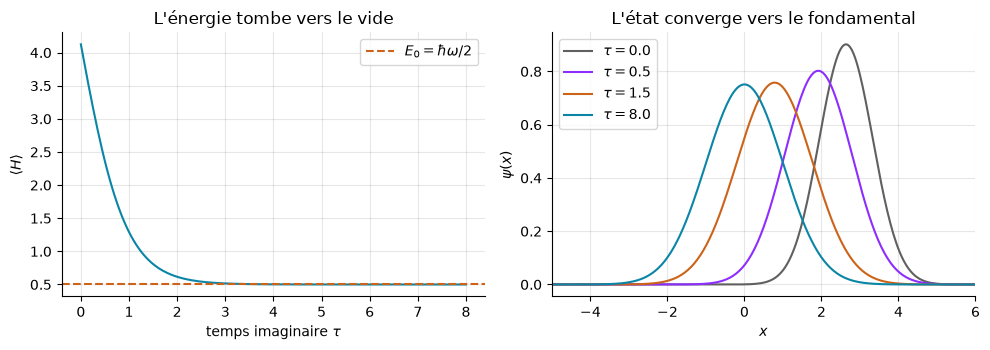

In [5]:
fig, (g, d) = plt.subplots(1, 2, figsize=(10, 3.6))
g.plot(taus, energies, color=S3)
g.axhline(0.5, color=O3, ls="--", label=r"$E_0 = \hbar\omega/2$")
g.set(xlabel=r"temps imaginaire $\tau$", ylabel=r"$\langle H \rangle$", title="L'énergie tombe vers le vide")
g.legend()
teintes = [K7, V5, O3, S3]
for (tau, p), col in zip(instantanes.items(), teintes):
    d.plot(x, p, color=col, label=fr"$\tau = {tau:.1f}$")
d.set(xlim=(-5, 6), xlabel="$x$", ylabel=r"$\psi(x)$", title="L'état converge vers le fondamental")
d.legend()
plt.tight_layout()

**Lecture.** Après quelques unités de temps imaginaire, il ne reste que l'état fondamental, et son énergie est $\tfrac{1}{2}\hbar\omega$, pas zéro. Un champ quantique est une infinité de tels oscillateurs : c'est le point de départ de [`../energie-du-vide/`](../energie-du-vide/).